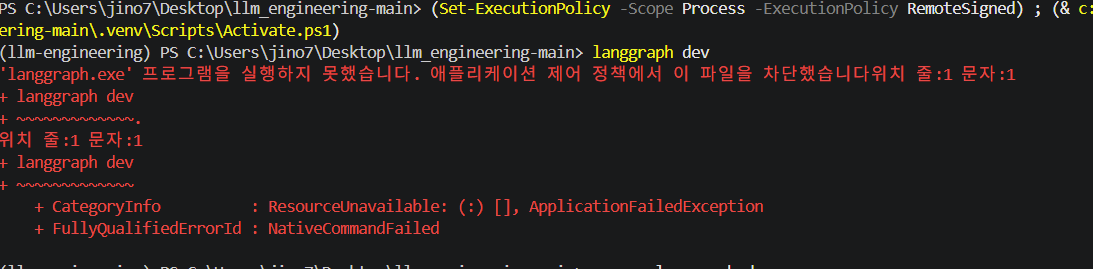

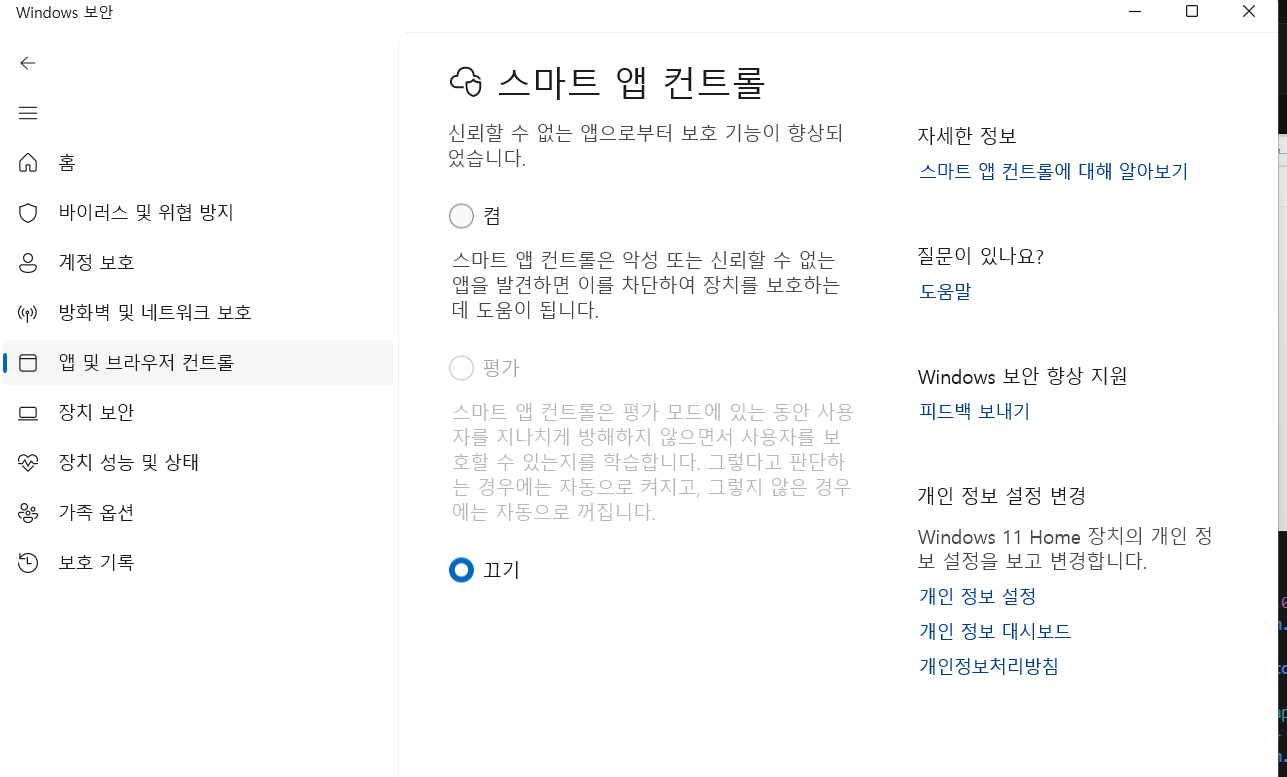


In [ ]:
! uv run langgraph dev

In [ ]:
from dotenv import load_dotenv

load_dotenv()

from langchain.tools import tool
from typing import Dict, Any
from tavily import TavilyClient

tavily_client = TavilyClient()

@tool
def web_search(query: str) -> Dict[str, Any]:

    """Search the web for information"""

    return tavily_client.search(query)

system_prompt = """

You are a personal chef. The user will give you a list of ingredients they have left over in their house.

Using the web search tool, search the web for recipes that can be made with the ingredients they have.

Return recipe suggestions and eventually the recipe instructions to the user, if requested.

"""

from langchain.agents import create_agent

agent = create_agent(
    model="gpt-5-nano",
    tools=[web_search],
    system_prompt=system_prompt
)

In [ ]:
{
    "dependencies": ["."],
    "graphs": {
        "agent": "./1.5_personal_chef.py:agent"
    },
    "env": "../../.env"
  }

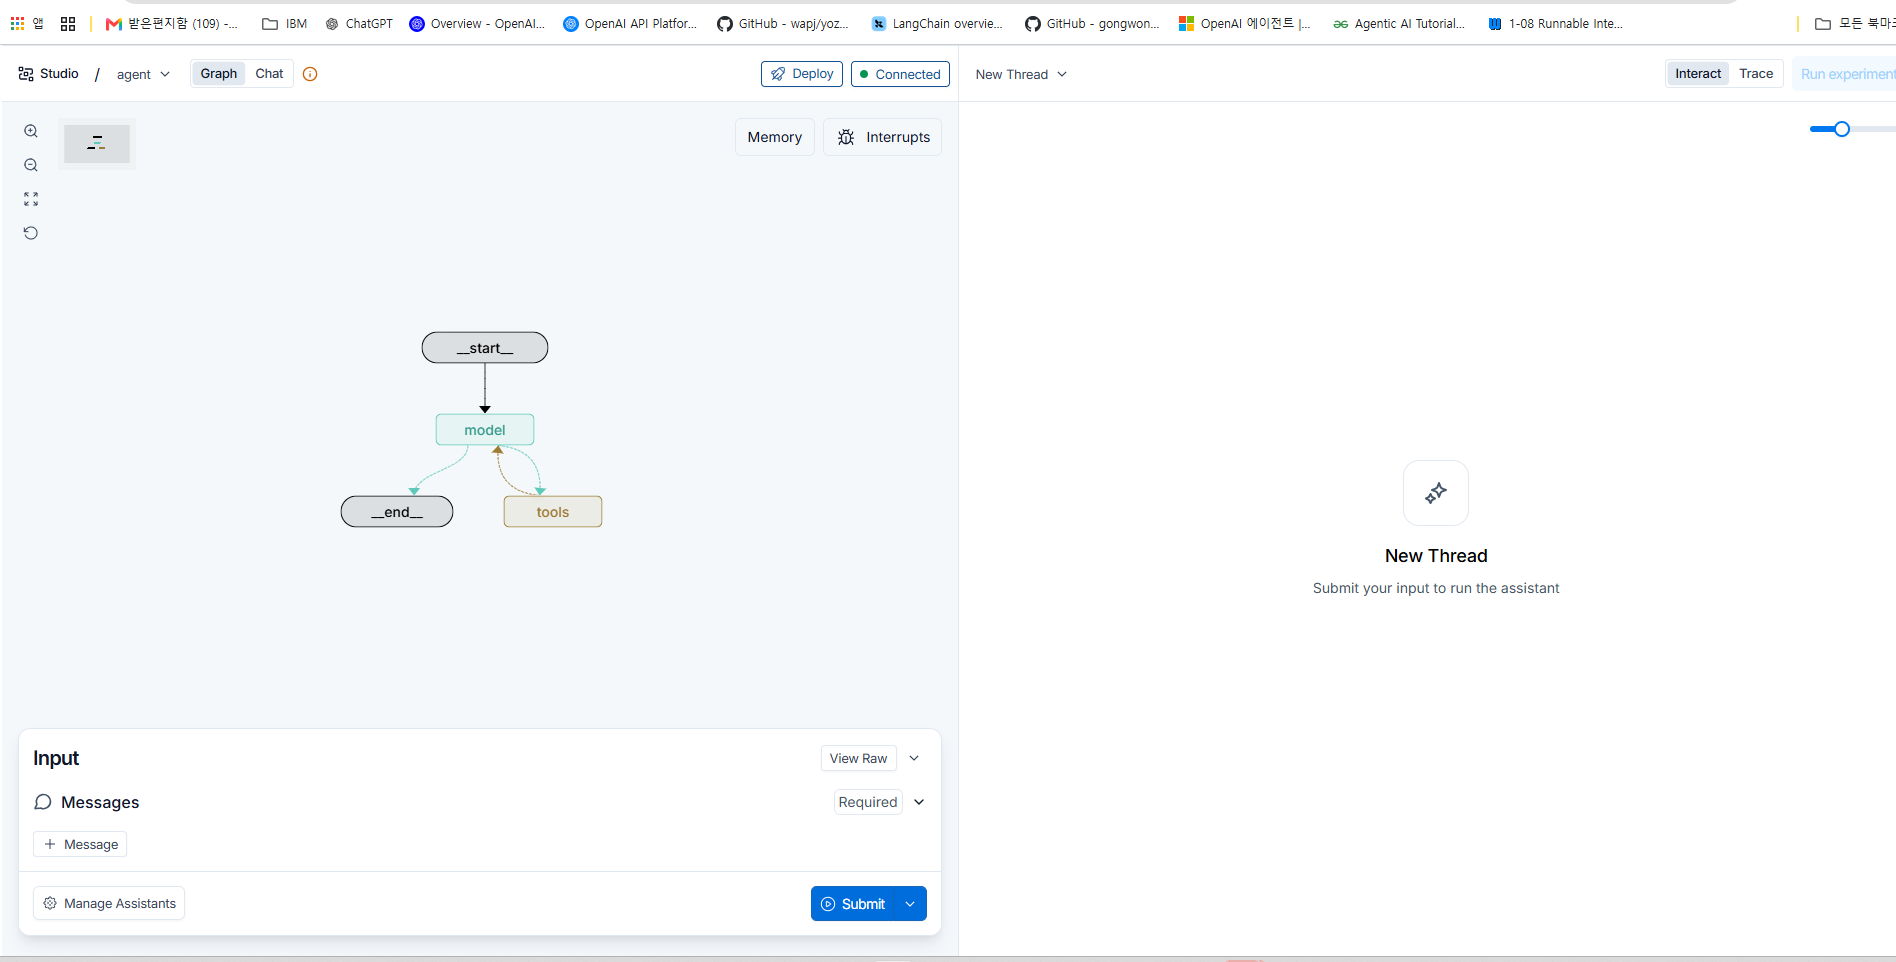